# Network Science HS26 – Enzyme Structural Graph

Analysis notebook. Run top to bottom; figures are saved to `../figures/`.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

DATA = Path("../raw_data/edgelist.txt")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
SEED = 42

## 0. Load the network

Note: the file lists every edge in both directions (220 rows, 110 unique edges). `nx.Graph` collapses these.

In [3]:
G = nx.read_edgelist(DATA, nodetype=int)
print(G)
print("rows in file:", sum(1 for _ in DATA.open()))
print("self-loops:", nx.number_of_selfloops(G))

Graph with 51 nodes and 110 edges
rows in file: 220
self-loops: 0


### Visual overview

Left: Kamada–Kawai layout (works well for small, sparse graphs), nodes coloured and sized by degree. Edges between consecutive node IDs (i, i+1) are drawn darker — 33 of the 50 possible pairs are linked, so the ID ordering appears to carry meaning (e.g. sequence position).
Right: adjacency matrix in node-ID order, which makes that ordering visible as a band along the diagonal plus off-diagonal stripes.

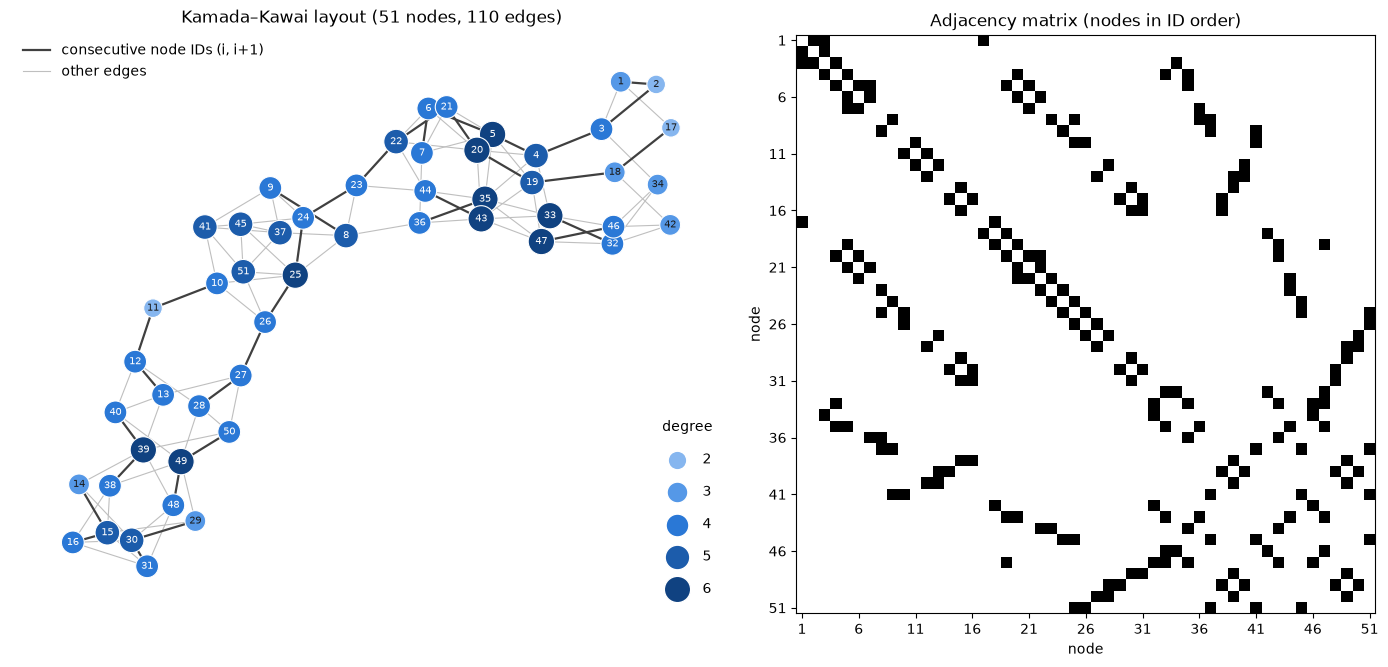

In [4]:
nodes = sorted(G.nodes())
deg = dict(G.degree())
pos = nx.kamada_kawai_layout(G)

# Degree only takes a few integer values (2–6): one discrete blue step per value, light -> dark
deg_vals = list(range(min(deg.values()), max(deg.values()) + 1))
deg_color = dict(zip(deg_vals, ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]))
def node_size(d):
    return 90 + 45 * d

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})

# Node-link drawing
seq_edges = [(u, v) for u, v in G.edges() if abs(u - v) == 1]
other_edges = [(u, v) for u, v in G.edges() if abs(u - v) != 1]
nx.draw_networkx_edges(G, pos, edgelist=other_edges, ax=ax1, edge_color="0.75", width=0.8)
nx.draw_networkx_edges(G, pos, edgelist=seq_edges, ax=ax1, edge_color="0.25", width=1.6)
nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax1,
                       node_color=[deg_color[deg[n]] for n in nodes],
                       node_size=[node_size(deg[n]) for n in nodes],
                       edgecolors="white", linewidths=0.8)
# Dark labels on the two lightest steps, white on the rest (keeps contrast readable)
light = deg_vals[1]
nx.draw_networkx_labels(G, pos, labels={n: n for n in nodes if deg[n] <= light},
                        ax=ax1, font_size=7, font_color="#1a1a1a")
nx.draw_networkx_labels(G, pos, labels={n: n for n in nodes if deg[n] > light},
                        ax=ax1, font_size=7, font_color="white")

deg_handles = [ax1.scatter([], [], s=node_size(d), color=deg_color[d], edgecolors="white", label=d)
               for d in deg_vals]
ax1.add_artist(ax1.legend(handles=deg_handles, title="degree", loc="lower right",
                          frameon=False, labelspacing=1.3, borderpad=1))
edge_handles = [plt.Line2D([], [], color="0.25", lw=1.6, label="consecutive node IDs (i, i+1)"),
                plt.Line2D([], [], color="0.75", lw=0.8, label="other edges")]
ax1.legend(handles=edge_handles, loc="upper left", frameon=False)
ax1.set_title(f"Kamada–Kawai layout ({G.number_of_nodes()} nodes, {G.number_of_edges()} edges)")
ax1.axis("off")

# Adjacency matrix in node-ID order
A = nx.to_numpy_array(G, nodelist=nodes)
ax2.imshow(A, cmap="Greys", interpolation="nearest")
ticks = np.arange(0, len(nodes), 5)
ax2.set_xticks(ticks, [nodes[i] for i in ticks])
ax2.set_yticks(ticks, [nodes[i] for i in ticks])
ax2.set_title("Adjacency matrix (nodes in ID order)")
ax2.set_xlabel("node")
ax2.set_ylabel("node")

fig.tight_layout()
fig.savefig(FIG / "network_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 1. Connectivity and global structure

## 2. Important or unusual nodes

## 3. Degree structure

## 4. Degree correlations (assortativity)

## 5. Local structure: triangles and clustering

## 6. Communities and mesoscopic structure

## 7. Comparison with random / small-world / scale-free models

## 8. Beyond the summary